# Analyzing Customer Satisfaction and Sales Trends

**Aim:** analyze customer satisfaction ratings and their relationship with sales performance, using descriptive statistics, correlation, hypothesis testing and visualization.

**Notebook outline**
1. Problem Statement
2. Dataset
3. Exploratory Data Analysis (EDA)
4. Statistical Analysis (correlation + t-test)
5. Advanced Visualization (heatmap)
6. Conclusion

## Step 1: Problem Statement

We aim to:
1. Introduce the variable descriptions.
2. Analyze the relationship between satisfaction levels and sales performance.
3. Use statistical techniques like descriptive statistics, correlation, and hypothesis testing.

**Main question:** *Do more satisfied customers generate higher monthly sales?*

## Step 2: Dataset

The dataset `customer_data` has the following columns:

| Column | Type | Description |
|---|---|---|
| `CustomerID` | Identifier | Unique identifier for customers |
| `Satisfaction` | Ordinal (1-5) | 1 = Very Unsatisfied, 5 = Very Satisfied |
| `MonthlySales` | Numerical | Monthly sales in USD |
| `Region` | Categorical | Geographical region (North, South, East, West) |

**Load the data.** Run the next cell and upload `customer_data 2.csv` when prompted (Colab). If you are running outside Colab, place the CSV next to the notebook.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)

# --- Load data: upload in Colab, otherwise read a local file ---
import glob, io
try:
    from google.colab import files
    uploaded = files.upload()                       # pick customer_data 2.csv
    fname = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[fname]))
except ImportError:
    fname = glob.glob("customer_data*.csv")[0]
    df = pd.read_csv(fname)

print(f"Loaded '{fname}'")
df.head()

Saving customer_data (2).csv to customer_data (2) (2).csv
Loaded 'customer_data (2) (2).csv'


,CustomerID,Satisfaction,MonthlySales,Region
0,1,3,534.18,North
1,2,5,687.62,North
2,3,4,595.04,South
3,4,3,442.31,West
4,5,2,410.16,East


In [31]:
# Structure, data types and data-quality checks
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate CustomerIDs:", df.CustomerID.duplicated().sum())
print("Satisfaction values:", sorted(df.Satisfaction.unique().tolist()))
print("Regions:", sorted(df.Region.unique()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   CustomerID    500 non-null    int64  
 1   Satisfaction  500 non-null    int64  
 2   MonthlySales  500 non-null    float64
 3   Region        500 non-null    object 
dtypes: float64(1), int64(2), object(1)
memory usage: 15.8+ KB

Missing values per column:
 CustomerID      0
Satisfaction    0
MonthlySales    0
Region          0
dtype: int64

Duplicate CustomerIDs: 0
Satisfaction values: [1, 2, 3, 4, 5]
Regions: ['East', 'North', 'South', 'West']


The data is clean: no missing values, no duplicate customers, satisfaction is always within 1-5 and there are four regions.

## Step 3: Exploratory Data Analysis (EDA)

### 3.1 Descriptive Statistics

In [32]:
# Overall summary of numeric columns
df[["Satisfaction", "MonthlySales"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Satisfaction,500.0,3.14,1.26,1.00,2.00,3.00,4.00,5.00
MonthlySales,500.0,500.76,100.71,230.31,434.91,496.73,566.13,807.89


In [33]:
# Extra measures for MonthlySales: spread, skewness, kurtosis
s = df.MonthlySales
print(f"Mean     : {s.mean():.2f}")
print(f"Median   : {s.median():.2f}")
print(f"Std Dev  : {s.std():.2f}")
print(f"Variance : {s.var():.2f}")
print(f"Range    : {s.min():.2f} - {s.max():.2f}")
print(f"IQR      : {s.quantile(.75) - s.quantile(.25):.2f}")
print(f"Skewness : {s.skew():.3f}")
print(f"Kurtosis : {s.kurt():.3f}")
print(f"\nSatisfaction mode: {df.Satisfaction.mode()[0]}   median: {df.Satisfaction.median()}")

Mean     : 500.76
Median   : 496.73
Std Dev  : 100.71
Variance : 10141.74
Range    : 230.31 - 807.89
IQR      : 131.23
Skewness : 0.156
Kurtosis : -0.175

Satisfaction mode: 3   median: 3.0


In [34]:
# Frequency tables for the categorical / ordinal variables
sat_counts = df.Satisfaction.value_counts().sort_index()
print(pd.DataFrame({"Count": sat_counts, "Percent": (sat_counts / len(df) * 100).round(1)}), "\n")

reg_counts = df.Region.value_counts()
print(pd.DataFrame({"Count": reg_counts, "Percent": (reg_counts / len(df) * 100).round(1)}))

              Count  Percent
Satisfaction                
1                65     13.0
2                89     17.8
3               139     27.8
4               124     24.8
5                83     16.6 

        Count  Percent
Region                
South     131     26.2
West      130     26.0
East      122     24.4
North     117     23.4


In [35]:
# Monthly sales summarized by satisfaction level and by region
print("Monthly sales by Satisfaction level")
display(df.groupby("Satisfaction").MonthlySales.agg(["count", "mean", "median", "std"]))

print("Monthly sales by Region")
display(df.groupby("Region").MonthlySales.agg(["count", "mean", "median", "std"]))

Monthly sales by Satisfaction level


,count,mean,median,std
Satisfaction,,,,
1,65,481.75,456.74,112.84
2,89,493.00,496.50,92.61
3,139,503.37,501.84,87.02
4,124,512.97,511.93,104.82
5,83,501.38,494.57,112.95


Monthly sales by Region


,count,mean,median,std
Region,,,,
East,122,505.78,497.44,92.94
North,117,500.41,504.70,109.40
South,131,502.18,505.57,97.02
West,130,494.95,483.93,104.02


### 3.2 Visualizations

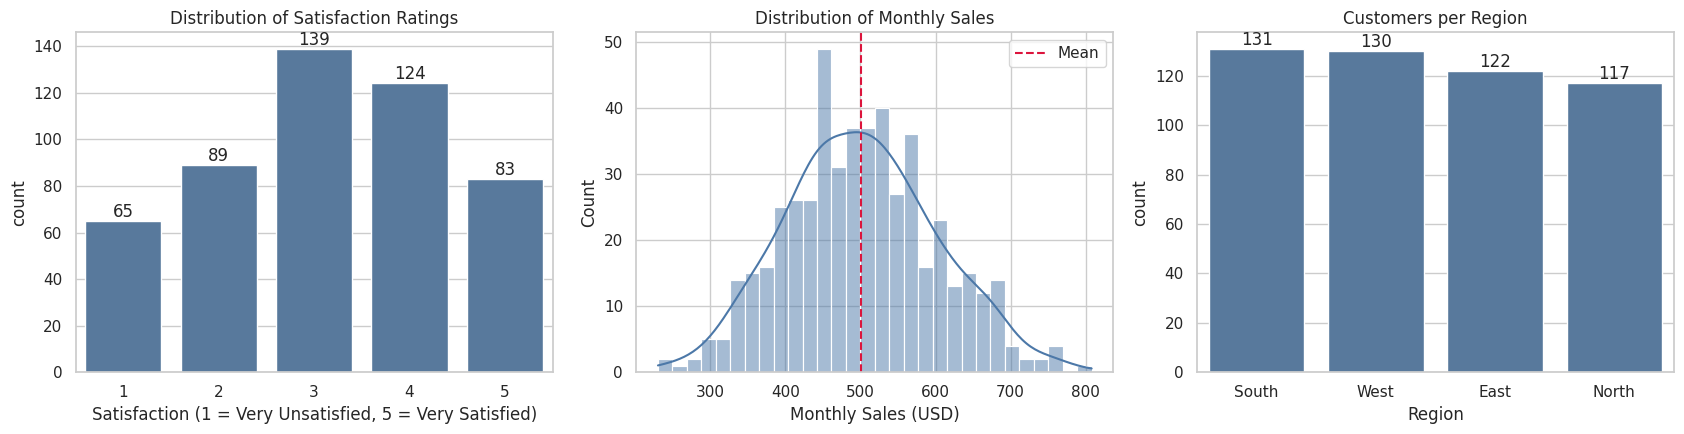

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Distribution of satisfaction
sns.countplot(data=df, x="Satisfaction", color="#4C78A8", ax=axes[0])
axes[0].set_title("Distribution of Satisfaction Ratings")
axes[0].set_xlabel("Satisfaction (1 = Very Unsatisfied, 5 = Very Satisfied)")
for c in axes[0].containers:
    axes[0].bar_label(c)

# Distribution of monthly sales
sns.histplot(df.MonthlySales, bins=30, kde=True, color="#4C78A8", ax=axes[1])
axes[1].axvline(df.MonthlySales.mean(), color="crimson", ls="--", label="Mean")
axes[1].set_title("Distribution of Monthly Sales")
axes[1].set_xlabel("Monthly Sales (USD)")
axes[1].legend()

# Customers per region
order = df.Region.value_counts().index
sns.countplot(data=df, x="Region", order=order, color="#4C78A8", ax=axes[2])
axes[2].set_title("Customers per Region")
for c in axes[2].containers:
    axes[2].bar_label(c)

plt.tight_layout()
plt.show()

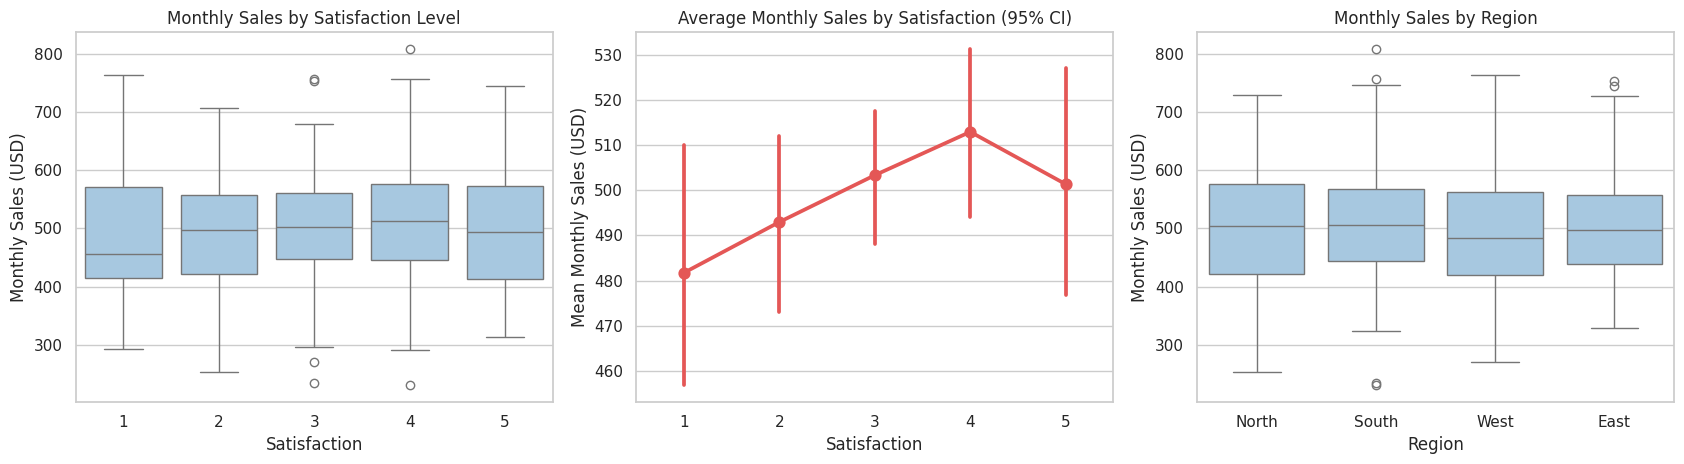

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Sales by satisfaction level
sns.boxplot(data=df, x="Satisfaction", y="MonthlySales", color="#9ecae9", ax=axes[0])
axes[0].set_title("Monthly Sales by Satisfaction Level")
axes[0].set_ylabel("Monthly Sales (USD)")

# Average sales by satisfaction level with 95% CI
sns.pointplot(data=df, x="Satisfaction", y="MonthlySales", errorbar=("ci", 95),
              color="#E45756", ax=axes[1])
axes[1].set_title("Average Monthly Sales by Satisfaction (95% CI)")
axes[1].set_ylabel("Mean Monthly Sales (USD)")

# Sales by region
sns.boxplot(data=df, x="Region", y="MonthlySales", color="#9ecae9", ax=axes[2])
axes[2].set_title("Monthly Sales by Region")
axes[2].set_ylabel("Monthly Sales (USD)")

plt.tight_layout()
plt.show()

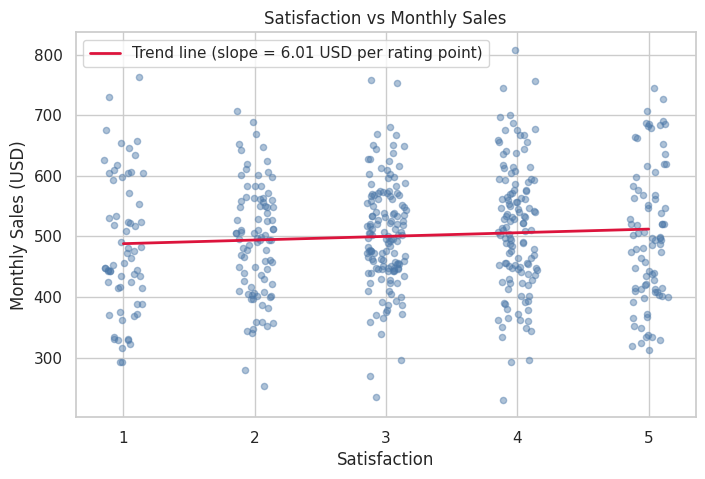

In [38]:
# Scatter plot with trend line (small jitter on x because satisfaction is discrete)
rng = np.random.default_rng(42)
plt.figure(figsize=(8, 5))
plt.scatter(df.Satisfaction + rng.uniform(-0.15, 0.15, len(df)), df.MonthlySales,
            alpha=0.45, s=20, color="#4C78A8")
m, b = np.polyfit(df.Satisfaction, df.MonthlySales, 1)
xs = np.linspace(1, 5, 100)
plt.plot(xs, m * xs + b, color="crimson", lw=2, label=f"Trend line (slope = {m:.2f} USD per rating point)")
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Satisfaction")
plt.ylabel("Monthly Sales (USD)")
plt.title("Satisfaction vs Monthly Sales")
plt.legend()
plt.show()

**EDA takeaways**
- Satisfaction ratings are spread across all five levels, with 3 the most common.
- Monthly sales are roughly bell-shaped (average about $500) with a few high-value customers.
- Customers are fairly evenly split across the four regions.
- Average sales rise a little from rating 1 to 4, but the groups overlap heavily. Testing whether this is a real effect next.

## Step 4: Statistical Analysis

### 4.1 Correlation Analysis

Satisfaction is **categorical**, so we report both:
- **Pearson r** (linear relationship), and
- **Spearman ρ** (rank-based, better suited to categorical data) and **Kendall τ**.

**Hypotheses** (for each test):

H₀: no relationship (correlation = 0);

H₁: correlation ≠ 0. Significance level α = 0.05.

In [39]:
pear_r, pear_p = stats.pearsonr(df.Satisfaction, df.MonthlySales)
spear_r, spear_p = stats.spearmanr(df.Satisfaction, df.MonthlySales)
kend_t, kend_p = stats.kendalltau(df.Satisfaction, df.MonthlySales)

corr_table = pd.DataFrame({
    "Coefficient": [pear_r, spear_r, kend_t],
    "p-value": [pear_p, spear_p, kend_p],
}, index=["Pearson r", "Spearman rho", "Kendall tau"])
corr_table["Significant at 0.05?"] = np.where(corr_table["p-value"] < 0.05, "Yes", "No")
display(corr_table.round(4))

print(f"\nPearson r squared = {pear_r**2:.4f}  -> satisfaction explains about {pear_r**2*100:.1f}% of the variation in sales")

,Coefficient,p-value,Significant at 0.05?
Pearson r,0.08,0.09,No
Spearman rho,0.06,0.15,No
Kendall tau,0.05,0.14,No



Pearson r squared = 0.0057  -> satisfaction explains about 0.6% of the variation in sales


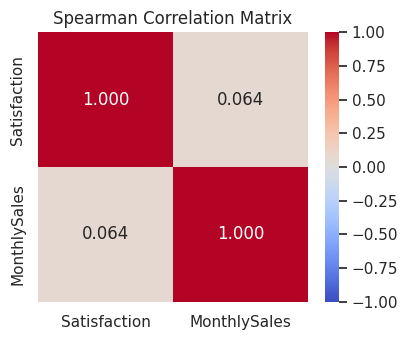

In [40]:
# Correlation matrix (Region excluded: categorical)
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(df[["Satisfaction", "MonthlySales"]].corr(method="spearman"),
            annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman Correlation Matrix")
plt.show()

### 4.2 Hypothesis Testing: Independent t-test

We split customers into two groups:
- **Satisfied**: rating 4-5
- **Unsatisfied**: rating 1-3


**H₀:** mean monthly sales are the same in both groups (μ_satisfied = μ_unsatisfied)


**H₁:** mean monthly sales differ (μ_satisfied ≠ μ_unsatisfied)
**α = 0.05** (two-tailed)

First we check the assumptions: roughly normal data (large samples, so the t-test is robust) and equal variances (Levene's test). If variances differ, Welch's t-test is the safer choice, so we report both.

In [41]:
df["Group"] = np.where(df.Satisfaction >= 4, "Satisfied (4-5)", "Unsatisfied (1-3)")
sat = df.loc[df.Group == "Satisfied (4-5)", "MonthlySales"]
uns = df.loc[df.Group == "Unsatisfied (1-3)", "MonthlySales"]

display(df.groupby("Group").MonthlySales.agg(["count", "mean", "std"]))

# Assumption checks
lev_stat, lev_p = stats.levene(sat, uns)
print(f"Levene test for equal variances: stat = {lev_stat:.3f}, p = {lev_p:.4f} ->",
      "variances differ" if lev_p < 0.05 else "variances similar")
print("Shapiro-Wilk normality p-values:  satisfied = %.3f,  unsatisfied = %.3f" %
      (stats.shapiro(sat).pvalue, stats.shapiro(uns).pvalue))

,count,mean,std
Group,,,
Satisfied (4-5),207,508.32,108.03
Unsatisfied (1-3),293,495.42,95.02


Levene test for equal variances: stat = 4.750, p = 0.0298 -> variances differ
Shapiro-Wilk normality p-values:  satisfied = 0.282,  unsatisfied = 0.941


In [42]:
# Independent t-tests: Student (equal variances) and Welch (unequal variances)
t_std = stats.ttest_ind(sat, uns, equal_var=True)
t_wel = stats.ttest_ind(sat, uns, equal_var=False)

diff = sat.mean() - uns.mean()
se = np.sqrt(sat.var(ddof=1)/len(sat) + uns.var(ddof=1)/len(uns))
ci_low, ci_high = diff - 1.96*se, diff + 1.96*se

# Cohen's d (effect size)
pooled_sd = np.sqrt(((len(sat)-1)*sat.var(ddof=1) + (len(uns)-1)*uns.var(ddof=1)) / (len(sat)+len(uns)-2))
cohen_d = diff / pooled_sd

results = pd.DataFrame({
    "t-statistic": [t_std.statistic, t_wel.statistic],
    "p-value": [t_std.pvalue, t_wel.pvalue],
}, index=["Student t-test", "Welch t-test"]).round(4)
display(results)

print(f"Mean difference (Satisfied - Unsatisfied): ${diff:.2f}")
print(f"Approx. 95% CI for the difference: (${ci_low:.2f}, ${ci_high:.2f})")
print(f"Cohen's d: {cohen_d:.3f}  (0.2 = small, 0.5 = medium, 0.8 = large)")

alpha = 0.05
p = t_wel.pvalue   # Welch used because Levene's test flagged unequal variances
print("\nDecision (alpha = 0.05):",
      "REJECT H0 - sales differ significantly between groups." if p < alpha
      else "FAIL TO REJECT H0 - no statistically significant difference in average sales.")

,t-statistic,p-value
Student t-test,1.41,0.16
Welch t-test,1.38,0.17


Mean difference (Satisfied - Unsatisfied): $12.90
Approx. 95% CI for the difference: ($-5.40, $31.20)
Cohen's d: 0.128  (0.2 = small, 0.5 = medium, 0.8 = large)

Decision (alpha = 0.05): FAIL TO REJECT H0 - no statistically significant difference in average sales.


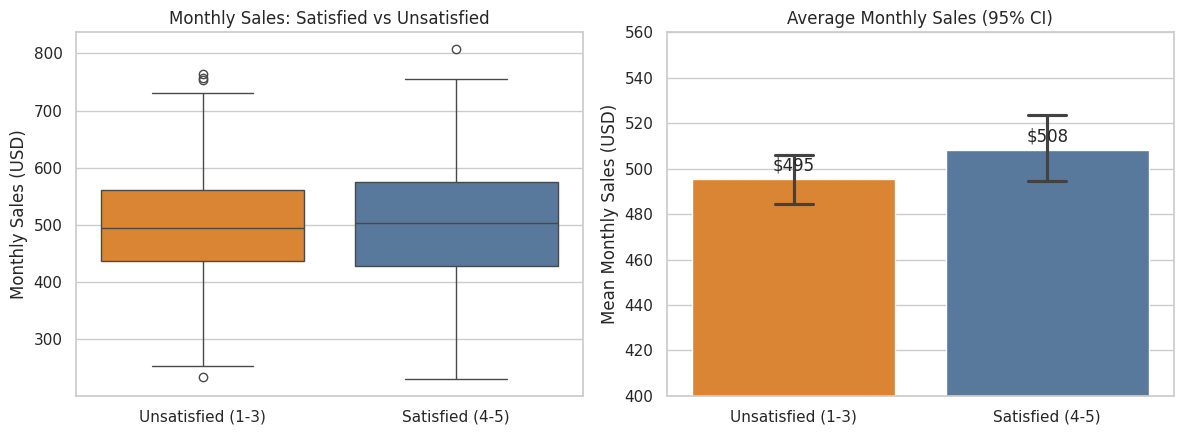

In [43]:
# Visualize the two-group comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=df, x="Group", y="MonthlySales", order=["Unsatisfied (1-3)", "Satisfied (4-5)"],
            hue="Group", palette=["#F58518", "#4C78A8"], legend=False, ax=axes[0])
axes[0].set_title("Monthly Sales: Satisfied vs Unsatisfied")
axes[0].set_ylabel("Monthly Sales (USD)"); axes[0].set_xlabel("")

sns.barplot(data=df, x="Group", y="MonthlySales", order=["Unsatisfied (1-3)", "Satisfied (4-5)"],
            errorbar=("ci", 95), hue="Group", palette=["#F58518", "#4C78A8"], legend=False, capsize=.15, ax=axes[1])
axes[1].set_title("Average Monthly Sales (95% CI)")
axes[1].set_ylabel("Mean Monthly Sales (USD)"); axes[1].set_xlabel("")
axes[1].set_ylim(400, 560)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="$%.0f", padding=3)

plt.tight_layout()
plt.show()

**Interpretation:** the satisfied group averages slightly more in sales, but the difference is small relative to the natural variation between customers, and the p-value is above 0.05. We **cannot conclude** that the difference is real rather than random chance.

## Step 5: Advanced Visualization

A heatmap of **average monthly sales** for each combination of Region (rows) and Satisfaction level (columns). The second heatmap shows how many customers sit in each cell, so we know how much to trust each average.

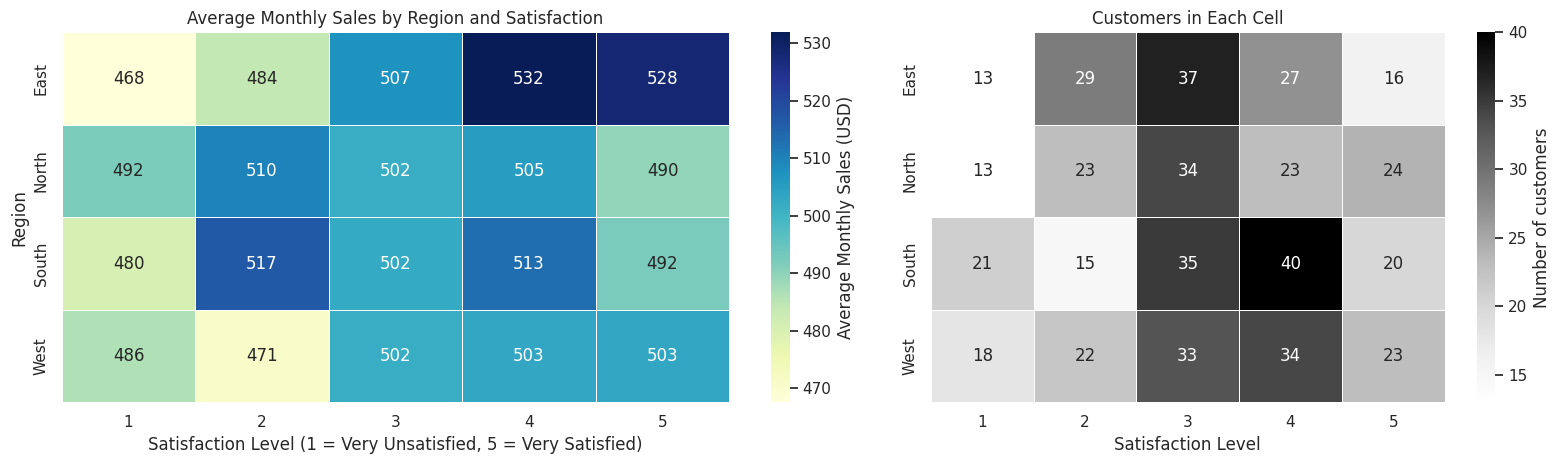

Satisfaction,1,2,3,4,5
Region,,,,,
East,467.6,484.1,507.5,531.9,528.0
North,492.0,509.9,501.6,505.2,489.6
South,480.2,516.7,502.3,513.1,492.3
West,486.4,470.9,501.7,503.1,503.0


In [44]:
pivot_mean = df.pivot_table(index="Region", columns="Satisfaction", values="MonthlySales", aggfunc="mean")
pivot_n = df.pivot_table(index="Region", columns="Satisfaction", values="MonthlySales", aggfunc="count")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

sns.heatmap(pivot_mean, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5,
            cbar_kws={"label": "Average Monthly Sales (USD)"}, ax=axes[0])
axes[0].set_title("Average Monthly Sales by Region and Satisfaction")
axes[0].set_xlabel("Satisfaction Level (1 = Very Unsatisfied, 5 = Very Satisfied)")
axes[0].set_ylabel("Region")

sns.heatmap(pivot_n, annot=True, fmt="d", cmap="Greys", linewidths=.5,
            cbar_kws={"label": "Number of customers"}, ax=axes[1])
axes[1].set_title("Customers in Each Cell")
axes[1].set_xlabel("Satisfaction Level")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

display(pivot_mean.round(1))

In [45]:
# Does the satisfaction-sales link look different by region? Correlation within each region
rows = []
for region, g in df.groupby("Region"):
    r, p = stats.spearmanr(g.Satisfaction, g.MonthlySales)
    rows.append({"Region": region, "n": len(g), "Spearman rho": r, "p-value": p,
                 "Significant at 0.05?": "Yes" if p < 0.05 else "No"})
display(pd.DataFrame(rows).set_index("Region").round(4))
print("Note: we are running 4 tests, so a stricter cut-off (Bonferroni: 0.05 / 4 = 0.0125) is fairer.")

,n,Spearman rho,p-value,Significant at 0.05?
Region,,,,
East,122,0.19,0.04,Yes
North,117,-0.03,0.73,No
South,131,0.04,0.62,No
West,130,0.09,0.32,No


Note: we are running 4 tests, so a stricter cut-off (Bonferroni: 0.05 / 4 = 0.0125) is fairer.


**Heatmap takeaways**
- No region shows a strong, consistent "more satisfied = more sales" pattern.
- The **East** region shows the clearest upward tilt (lowest sales at rating 1, highest at 4-5). Its within-region correlation is nominally significant (p ≈ 0.04), but because we ran four regional tests, a fairer cut-off is 0.0125, which East does not pass. Treat it as a lead worth checking, not a finding. Some cells also have few customers (13-16), so individual cell averages are noisy.
- North and South are essentially flat across satisfaction levels.

## Step 6: Conclusion (in plain language)

**What we looked at:** 500 customers, each with a satisfaction rating (1-5), monthly sales, and a region. We asked whether happier customers buy more.

**What we found**

1. **Typical customer:** average rating is about 3.1 out of 5 and average monthly sales about $500. Customers are spread evenly across the four regions.

2. **Is there a link between satisfaction and sales?** Only a very faint one. The correlation is about 0.07 (on a scale where 0 means no link and 1 means a perfect link). Satisfaction explains well under 1% of why one customer's sales differ from another's. This is not statistically significant at the usual 5% level, so it could easily be random chance.

3. **Satisfied (4-5) vs Unsatisfied (1-3) customers:** satisfied customers spend about 13 dollars more per month on average (508 dollars vs 495 dollars). That gap is small compared with how much sales vary from customer to customer (a typical spread of about $100), and the t-test says it is **not statistically significant** (p ≈ 0.16).

4. **By region:** the pattern is similar everywhere. East shows the clearest hint that happier customers spend more, and it looks significant on its own, but after allowing for the fact that we checked four regions, it is not convincing. It is worth a closer look with more data.

**Bottom line:** in this dataset, **customer satisfaction is not a reliable predictor of monthly sales.** Happier customers spend slightly more on average, but the difference is too small to tell apart from chance.

**What this means for the business**
- Don't expect satisfaction scores alone to forecast or drive sales.
- Other factors (product mix, pricing, customer size, contract type, etc.) probably matter more. Collecting that data would be a good next step.
- A larger sample, or tracking the same customers over time, would help show whether a small real effect exists.

**Limitations:** this is observational data, so even a real link would not prove that satisfaction *causes* higher sales. Satisfaction is a 1-5 self-reported rating, and some region-by-rating groups are small.